# AI204 Deep RL: LunarLander with DQN

Pipeline:
1. train a DQN agent
2. save/load the trained model
3. evaluate random vs trained behavior
4. create an MP4 video
5. save and display one frame from the trained model

In [1]:
import os
from pathlib import Path

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import torch

from IPython.display import Video, Image, display

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
# GPU / CPU check

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Using device:", DEVICE)


PyTorch version: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 2060
Using device: cuda


In [3]:
# Basic configuration

ENV_ID = "LunarLander-v3"

# We use 10.000 for a quick test.
# We use 100.000+ for the final experiment.
TOTAL_TIMESTEPS = 500_000

EVAL_EPISODES = 10
SEED = 159 # My AEM as a seed

BASE_DIR = Path("lunarlander_dqn_results")
LOG_DIR = BASE_DIR / "logs"
MODEL_DIR = BASE_DIR / "models"
VIDEO_DIR = BASE_DIR / "videos"
FRAME_DIR = BASE_DIR / "frames"

LOG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
FRAME_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "dqn_lunarlander"
MONITOR_PATH = LOG_DIR / "monitor.csv"

print("Environment:", ENV_ID)
print("Timesteps:", TOTAL_TIMESTEPS)


Environment: LunarLander-v3
Timesteps: 500000


In [4]:
def make_env(render_mode = None, monitor = False):
    env = gym.make(ENV_ID, render_mode = render_mode)

    if monitor:
        env = Monitor(env, filename = str(MONITOR_PATH))

    return env


In [5]:
# Random-agent baseline

random_env = make_env(render_mode=None)

random_rewards = []

for episode in range(EVAL_EPISODES):
    obs, info = random_env.reset(seed = SEED + episode)
    done = False
    total_reward = 0

    while not done:
        action = random_env.action_space.sample()
        obs, reward, terminated, truncated, info = random_env.step(action)
        total_reward += reward
        done = terminated or truncated

    random_rewards.append(total_reward)

random_env.close()

random_mean_reward = np.mean(random_rewards)
random_std_reward = np.std(random_rewards)

print(f"Random agent mean reward: {random_mean_reward:.2f}")
print(f"Random agent reward std:  {random_std_reward:.2f}")


<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type swigvarlink has no __module__ attribute


Random agent mean reward: -173.23
Random agent reward std:  93.64


In [6]:
# Train DQN

train_env = make_env(render_mode = None, monitor = True)

model = DQN(
    policy = "MlpPolicy",
    env = train_env,
    learning_rate = 1e-3,
    buffer_size = 100_000,
    learning_starts = 5_000,
    batch_size = 64,
    gamma = 0.99,
    train_freq = 4,
    gradient_steps = 1,
    target_update_interval = 1_000,
    exploration_fraction = 0.25,
    exploration_final_eps = 0.05,
    policy_kwargs = dict(net_arch=[256, 256]),
    seed = SEED,
    verbose = 1,
    device = DEVICE,
)

model.learn(total_timesteps=TOTAL_TIMESTEPS)

model.save(str(MODEL_PATH))
train_env.close()

print(f"Saved model to: {MODEL_PATH}.zip")


Using cuda device
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 88.2     |
|    ep_rew_mean      | -174     |
|    exploration_rate | 0.997    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4329     |
|    time_elapsed     | 0        |
|    total_timesteps  | 353      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 86.2     |
|    ep_rew_mean      | -222     |
|    exploration_rate | 0.995    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 4421     |
|    time_elapsed     | 0        |
|    total_timesteps  | 690      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 93.7     |
|    ep_rew_mean      | -189     |
|    exploration_rate | 0.991    |
| 

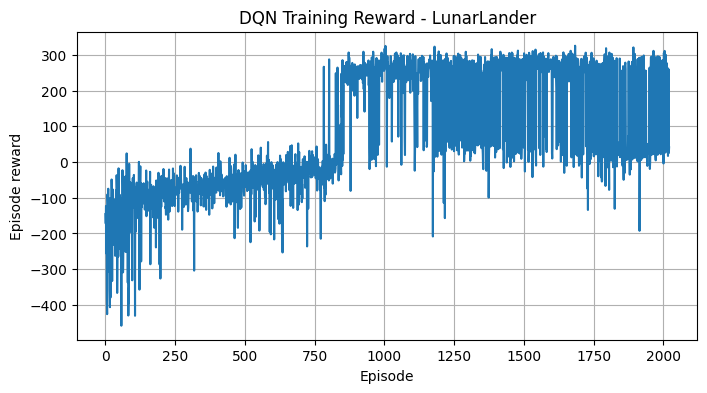

,Reward,Length,Time (s)
2012,277.634788,379,795.637701
2013,34.502349,104,795.815944
2014,49.987644,128,796.041977
2015,40.391777,90,796.197102
2016,263.212961,199,796.528833
2017,17.160051,113,796.724514
2018,69.352445,139,796.944553
2019,260.286778,186,797.258649
2020,25.354803,102,797.470689
2021,41.167383,129,797.703243


In [7]:
# Plot training reward curve

if MONITOR_PATH.exists():
    rewards_df = pd.read_csv(MONITOR_PATH, skiprows=1)

    plt.figure(figsize=(8, 4))
    plt.plot(rewards_df["r"].values)
    plt.xlabel("Episode")
    plt.ylabel("Episode reward")
    plt.title("DQN Training Reward - LunarLander")
    plt.grid(True)
    plt.show()

    clean_df = rewards_df.rename(columns = {
        "r" : "Reward",
        "l" : "Length",
        "t" : "Time (s)"
    })

    display(clean_df.tail(10))
else:
    print("Monitor file was not found:", MONITOR_PATH)


In [8]:
# Load and evaluate trained model

eval_env = make_env(render_mode = None)

trained_model = DQN.load(str(MODEL_PATH), env=eval_env, device=DEVICE)

trained_mean_reward, trained_std_reward = evaluate_policy(
    trained_model,
    eval_env,
    n_eval_episodes = EVAL_EPISODES,
    deterministic = True,
)

eval_env.close()

print(f"Random agent mean reward: {random_mean_reward:.2f}")
print(f"Trained DQN mean reward:  {trained_mean_reward:.2f}")
print(f"Trained DQN reward std:   {trained_std_reward:.2f}")


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


c:\Users\sfars\Desktop\DMCI- AUTh\Semester2\DMCI201-DeepLearning\Project_Deep_RL\.venv\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Random agent mean reward: -173.23
Trained DQN mean reward:  196.50
Trained DQN reward std:   115.58


In [9]:
# Comparison table

comparison = pd.DataFrame({
    "Agent": ["Random agent", "Trained DQN agent"],
    "Mean reward": [random_mean_reward, trained_mean_reward],
    "Reward std": [random_std_reward, trained_std_reward],
})

display(comparison)


,Agent,Mean reward,Reward std
0,Random agent,-173.229068,93.636920
1,Trained DQN agent,196.498271,115.578412


In [10]:
def record_agent_mp4(model=None, filename="agent.mp4", fps=30, max_steps=1_000, deterministic=True):
    env = make_env(render_mode="rgb_array")

    frames = []
    obs, info = env.reset(seed=SEED)
    done = False
    steps = 0

    while not done and steps < max_steps:
        frame = env.render()
        frames.append(frame)

        if model is None:
            action = env.action_space.sample()
        else:
            action, _ = model.predict(obs, deterministic = deterministic)

        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        steps += 1

    env.close()

    output_path = VIDEO_DIR / filename
    imageio.mimsave(output_path, frames, fps = fps, macro_block_size = 16)

    print(f"Saved video: {output_path}")
    print(f"Frames: {len(frames)}")

    return output_path


In [11]:
# Create and display random-agent MP4

random_video_path = record_agent_mp4(
    model = None,
    filename = "random_lunarlander.mp4",
    fps = 30,
)

display(Video(str(random_video_path), embed=True))


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Saved video: lunarlander_dqn_results\videos\random_lunarlander.mp4
Frames: 80


In [12]:
# Create and display trained-agent MP4

trained_video_path = record_agent_mp4(
    model = trained_model,
    filename = "trained_dqn_lunarlander.mp4",
    fps = 30,
)

display(Video(str(trained_video_path), embed=True))


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Saved video: lunarlander_dqn_results\videos\trained_dqn_lunarlander.mp4
Frames: 193


Saved frame: lunarlander_dqn_results\frames\trained_lunarlander_frame.png


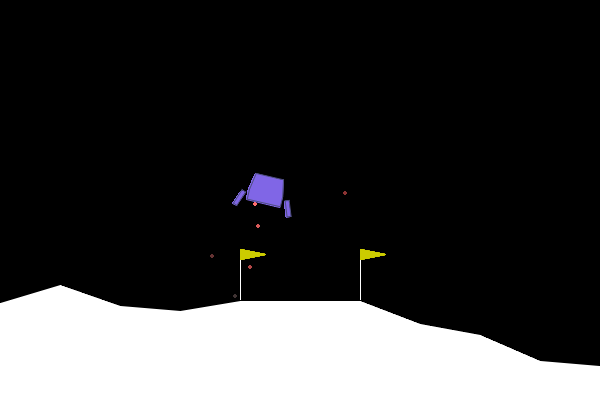

In [13]:
# Save and display one frame from the trained model

def save_trained_model_frame(model, filename = "trained_lunarlander_frame.png", target_step = 80):
    env = make_env(render_mode="rgb_array")

    obs, info = env.reset(seed = SEED)
    frame = env.render()

    for _ in range(target_step):
        action, _ = model.predict(obs, deterministic = True)
        obs, reward, terminated, truncated, info = env.step(action)
        frame = env.render()

        if terminated or truncated:
            break

    env.close()

    frame_path = FRAME_DIR / filename
    imageio.imwrite(frame_path, frame)

    print(f"Saved frame: {frame_path}")
    return frame_path

frame_path = save_trained_model_frame(
    trained_model,
    filename = "trained_lunarlander_frame.png",
    target_step = 80,
)

display(Image(filename = str(frame_path)))


In [14]:
# Οpen live game window.
# This works better in a local IDE or terminal than inside a notebook.

live_env = make_env(render_mode = "human")
obs, info = live_env.reset(seed = SEED)
done = False

while not done:
    action, _ = trained_model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = live_env.step(action)
    done = terminated or truncated

live_env.close()
